# Drift-Diffusion Model (DDM) for Decision Making
This notebook simulates a simple Drift-Diffusion Model, widely used in computational neuroscience to model two-alternative forced-choice (2AFC) tasks.

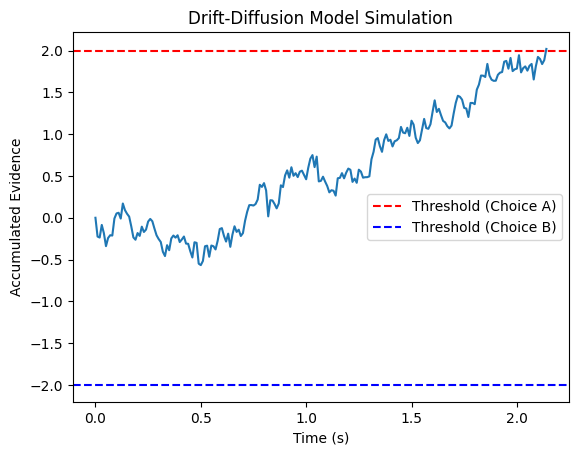

In [1]:
import numpy as np
import matplotlib.pyplot as plt

def simulate_ddm(drift_rate, noise_std, threshold, dt=0.01, max_time=5.0):
    time_steps = int(max_time / dt)
    evidence = np.zeros(time_steps)
    for t in range(1, time_steps):
        evidence[t] = evidence[t-1] + drift_rate * dt + noise_std * np.sqrt(dt) * np.random.randn()
        if np.abs(evidence[t]) >= threshold:
            return evidence[:t+1], np.arange(t+1) * dt
    return evidence, np.arange(time_steps) * dt

evidence, time = simulate_ddm(drift_rate=0.5, noise_std=1.0, threshold=2.0)
plt.plot(time, evidence)
plt.axhline(2.0, color='r', linestyle='--', label='Threshold (Choice A)')
plt.axhline(-2.0, color='b', linestyle='--', label='Threshold (Choice B)')
plt.xlabel('Time (s)')
plt.ylabel('Accumulated Evidence')
plt.title('Drift-Diffusion Model Simulation')
plt.legend()
plt.show()